In [1]:

# Import the required libraries
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

from torch_geometric.data import Data

# Set project paths
PROJECT_DIR = Path.cwd().parent
PROCESSED_DIR = PROJECT_DIR / "notebooks" / "data" / "processed"

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Libraries imported successfully!")


Device: cpu
Libraries imported successfully!


In [2]:

# Load the processed T-Finance dataset
export = torch.load(
    PROCESSED_DIR / "tfinance_pyg_export.pt",
    map_location="cpu",
    weights_only=True
)

# Create graph data
data = Data(
    x=export["x"],
    y=export["y"],
    edge_index=export["edge_index"]
)

# Load experimental splits
splits = torch.load(
    PROCESSED_DIR / "experimental_splits.pt",
    map_location="cpu",
    weights_only=True
)

train_idx = splits["train_idx"]
val_idx = splits["val_idx"]
test_idx = splits["test_idx"]

labelled_1 = splits["labelled_1"]
unlabelled_1 = splits["unlabelled_1"]

labelled_5 = splits["labelled_5"]
unlabelled_5 = splits["unlabelled_5"]

print("Dataset loaded successfully!")
print("Number of nodes:", data.x.shape[0])
print("Number of features:", data.x.shape[1])
print("Number of edges:", data.edge_index.shape[1])
print("Number of fraud cases:", (data.y == 1).sum().item())


Dataset loaded successfully!
Number of nodes: 39357
Number of features: 10
Number of edges: 42445086
Number of fraud cases: 1804


In [3]:

class AdaptiveNeighbourTrust(nn.Module):

    def __init__(self, hidden_dim):
        super().__init__()

        self.trust_network = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()
        )

    def forward(self, center_features, neighbour_features):

        # Combine centre and neighbour representations
        combined = torch.cat(
            [center_features, neighbour_features], dim=1
        )

        # Calculate trust score between 0 and 1
        trust_scores = self.trust_network(combined)

        return trust_scores


In [4]:

# Create the ANT module
ant_module = AdaptiveNeighbourTrust(hidden_dim=32)

# Create sample centre and neighbour representations
center_features = torch.randn(5, 32)
neighbour_features = torch.randn(5, 32)

# Calculate trust scores
trust_scores = ant_module(
    center_features,
    neighbour_features
)

print("Trust scores:")
print(trust_scores.detach().squeeze())

print("\nMinimum trust:", trust_scores.min().item())
print("Maximum trust:", trust_scores.max().item())


Trust scores:
tensor([0.3717, 0.4565, 0.4644, 0.5192, 0.4569])

Minimum trust: 0.3717171549797058
Maximum trust: 0.5191746354103088


In [5]:

class TrustWeightedAggregation(nn.Module):

    def forward(self, center_features, neighbour_features, trust_scores):

        # Give more weight to trusted neighbours
        weighted_neighbours = neighbour_features * trust_scores

        # Aggregate neighbour information
        aggregated = weighted_neighbours.mean(dim=0)

        # Combine with centre node
        updated_features = center_features.mean(dim=0) + aggregated

        return updated_features


In [6]:

class ANTModule(nn.Module):

    def __init__(self, hidden_dim):
        super().__init__()

        self.trust = AdaptiveNeighbourTrust(hidden_dim)
        self.aggregation = TrustWeightedAggregation()

    def forward(self, center_features, neighbour_features):

        # Calculate neighbour trust
        trust_scores = self.trust(
            center_features,
            neighbour_features
        )

        # Aggregate using trust scores
        updated_features = self.aggregation(
            center_features,
            neighbour_features,
            trust_scores
        )

        return updated_features, trust_scores


# Create ANT module
ant = ANTModule(hidden_dim=32)

print("ANT module created successfully!")


ANT module created successfully!


In [7]:

# Generate sample node representations
center_features = torch.randn(5, 32)
neighbour_features = torch.randn(5, 32)

# Run the ANT module
updated_features, trust_scores = ant(
    center_features,
    neighbour_features
)

print("Trust scores:")
print(trust_scores.detach().squeeze())

print("\nUpdated feature shape:")
print(updated_features.shape)

print("\nANT test completed successfully!")


Trust scores:
tensor([0.4901, 0.4501, 0.4924, 0.4355, 0.5183])

Updated feature shape:
torch.Size([32])

ANT test completed successfully!


In [8]:

class ANTCGNN(nn.Module):

    def __init__(self, input_dim=10, hidden_dim=64,
                 attention_dim=32, num_classes=2):

        super().__init__()

        self.csd = CategorySemanticDecomposition(
            input_dim, hidden_dim
        )

        self.attention = DenoisingAttention(
            hidden_dim // 2, attention_dim
        )

        self.trust = AdaptiveNeighbourTrust(
            hidden_dim // 2
        )

        self.classifier = CGNNClassifier(
            input_dim=hidden_dim // 2,
            hidden_dim=64,
            num_classes=num_classes
        )

        self.update_projection = nn.Linear(
            hidden_dim // 2, hidden_dim // 2
        )

    def forward(self, x, edge_index):

        # 1. Category Semantic Decomposition
        normal, abnormal = self.csd(x)

        # 2. Denoising Attention
        messages, alpha = self.attention(
            normal, abnormal, edge_index
        )

        # 3. Identify centre and neighbour nodes
        src, dst = edge_index

        center_features = normal[dst]
        neighbour_features = messages

        # 4. Calculate adaptive neighbour trust
        trust_scores = self.trust(
            center_features, neighbour_features
        )

        # 5. Trust-weighted aggregation
        weighted_messages = messages * trust_scores

        neighbour_sum = torch.zeros_like(normal)

        neighbour_sum.index_add_(
            0, dst, weighted_messages
        )

        degree = torch.bincount(
            dst, minlength=x.size(0)
        ).to(x.dtype)

        degree_norm = degree.clamp(min=1).sqrt().unsqueeze(1)

        combined = normal + neighbour_sum / degree_norm

        updated_features = self.update_projection(combined)

        # 6. Fraud classification
        logits = self.classifier(updated_features)

        return logits, trust_scores, alpha


In [10]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.utils import softmax


class CategorySemanticDecomposition(nn.Module):
    def __init__(self, input_dim=10, hidden_dim=64):
        super().__init__()
        assert hidden_dim % 2 == 0

        half_dim = hidden_dim // 2

        self.input_projection = nn.Linear(input_dim, hidden_dim)
        self.normal_projection = nn.Linear(half_dim, half_dim)
        self.abnormal_projection = nn.Linear(half_dim, half_dim)
        self.activation = nn.LeakyReLU()

    def forward(self, x):
        h = self.activation(self.input_projection(x))
        first_half, second_half = torch.chunk(h, 2, dim=1)

        normal = self.normal_projection(first_half)
        abnormal = self.abnormal_projection(second_half)

        return normal, abnormal


class DenoisingAttention(nn.Module):
    def __init__(self, hidden_dim=32, attention_dim=32):
        super().__init__()
        self.attention_projection = nn.Linear(hidden_dim, attention_dim)
        self.attention_score = nn.Linear(attention_dim, 1, bias=False)

    def forward(self, normal, abnormal, edge_index):
        src, dst = edge_index
        combined = normal[src] + abnormal[src]
        hidden = torch.tanh(self.attention_projection(combined))
        scores = self.attention_score(hidden)

        alpha = softmax(scores, index=dst, num_nodes=normal.size(0))

        messages = alpha * normal[src] + (1 - alpha) * abnormal[src]
        return messages, alpha


class AggregationUpdate(nn.Module):
    def __init__(self, hidden_dim=32):
        super().__init__()
        self.update_projection = nn.Linear(hidden_dim, hidden_dim)

    def forward(self, center_features, messages, edge_index):
        num_nodes = center_features.size(0)
        src, dst = edge_index

        neighbour_sum = torch.zeros_like(center_features)
        neighbour_sum.index_add_(0, dst, messages)

        degree = torch.bincount(dst, minlength=num_nodes).to(center_features.dtype)
        degree_norm = degree.clamp(min=1).sqrt().unsqueeze(1)

        combined = center_features + neighbour_sum / degree_norm
        return self.update_projection(combined)


class CGNNClassifier(nn.Module):
    def __init__(self, input_dim=32, hidden_dim=64, num_classes=2):
        super().__init__()
        self.classifier = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x):
        return self.classifier(x)


In [11]:

# Initialize ANT-CGNN
model = ANTCGNN(
    input_dim=10,
    hidden_dim=64,
    attention_dim=32,
    num_classes=2
)

# Create a small sample graph
sample_x = torch.randn(8, 10)

sample_edge_index = torch.tensor([
    [0, 1, 2, 3, 4, 5, 6, 7],
    [1, 2, 3, 4, 5, 6, 7, 0]
], dtype=torch.long)

# Forward pass
logits, trust_scores, attention_scores = model(
    sample_x, sample_edge_index
)

print("Model test completed!")
print("Logits shape:", logits.shape)
print("Trust scores shape:", trust_scores.shape)
print("Attention scores shape:", attention_scores.shape)
print("Trust score range:",
      trust_scores.min().item(),
      "to",
      trust_scores.max().item())


Model test completed!
Logits shape: torch.Size([8, 2])
Trust scores shape: torch.Size([8, 1])
Attention scores shape: torch.Size([8, 1])
Trust score range: 0.48982325196266174 to 0.5222298502922058


In [12]:

# Move model to the selected device
model = model.to(device)

# Adam optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=1e-4
)

# Classification loss
criterion = nn.CrossEntropyLoss()

print("Model:", "ANT-CGNN")
print("Device:", device)
print("Optimizer: Adam")
print("Learning rate: 0.01")
print("Weight decay: 0.0001")
print("Training setup ready!")


Model: ANT-CGNN
Device: cpu
Optimizer: Adam
Learning rate: 0.01
Weight decay: 0.0001
Training setup ready!


In [13]:

# Generate sample labels for 8 nodes
sample_labels = torch.tensor(
    [0, 0, 1, 0, 1, 0, 0, 1],
    dtype=torch.long
).to(device)

sample_x = sample_x.to(device)
sample_edge_index = sample_edge_index.to(device)

# Training mode
model.train()

# Forward pass
optimizer.zero_grad()

logits, trust_scores, attention_scores = model(
    sample_x, sample_edge_index
)

# Calculate classification loss
loss = criterion(logits, sample_labels)

# Backpropagation
loss.backward()

# Update model parameters
optimizer.step()

print("Training test completed!")
print("Loss:", loss.item())
print("Gradients calculated:", any(
    p.grad is not None for p in model.parameters()
))


Training test completed!
Loss: 0.6891151070594788
Gradients calculated: True


In [14]:

# Locate the existing neighbour index
INDEX_DIR = PROCESSED_DIR / "neighbour_index"

OFFSETS_PATH = INDEX_DIR / "offsets.npy"
NEIGHBORS_PATH = INDEX_DIR / "neighbors.npy"

offsets = np.load(OFFSETS_PATH, mmap_mode="r")
neighbors = np.load(NEIGHBORS_PATH, mmap_mode="r")

print("Neighbour index loaded!")
print("Number of nodes:", len(offsets) - 1)
print("Number of indexed edges:", len(neighbors))


Neighbour index loaded!
Number of nodes: 39357
Number of indexed edges: 42445086


In [15]:

def sample_neighbors(seed_nodes, num_neighbors=10):

    sampled_edges = []
    sampled_nodes = set(seed_nodes.tolist())

    for node in seed_nodes.tolist():

        start = offsets[node]
        end = offsets[node + 1]

        node_neighbors = neighbors[start:end]

        if len(node_neighbors) > num_neighbors:
            selected = np.random.choice(
                node_neighbors,
                size=num_neighbors,
                replace=False
            )
        else:
            selected = node_neighbors

        for neighbor in selected:
            neighbor = int(neighbor)

            sampled_edges.append((neighbor, node))
            sampled_nodes.add(neighbor)

    if sampled_edges:
        sampled_edge_index = torch.tensor(
            sampled_edges,
            dtype=torch.long
        ).t().contiguous()
    else:
        sampled_edge_index = torch.empty(
            (2, 0),
            dtype=torch.long
        )

    sampled_nodes = torch.tensor(
        sorted(sampled_nodes),
        dtype=torch.long
    )

    return sampled_nodes, sampled_edge_index


In [16]:

# Select five centre nodes
sample_seed_nodes = train_idx[:5].cpu()

# Sample their neighbours
sampled_nodes, sampled_edges = sample_neighbors(
    sample_seed_nodes,
    num_neighbors=10
)

print("Centre nodes:", len(sample_seed_nodes))
print("Sampled nodes:", len(sampled_nodes))
print("Sampled edges:", sampled_edges.shape[1])


Centre nodes: 5
Sampled nodes: 55
Sampled edges: 50


In [17]:

def prepare_batch(seed_nodes, num_neighbors=10):

    sampled_nodes, sampled_edges = sample_neighbors(
        seed_nodes,
        num_neighbors
    )

    # Map global node IDs to local batch IDs
    node_mapping = {
        int(node): i
        for i, node in enumerate(sampled_nodes.tolist())
    }

    local_edges = torch.tensor(
        [
            [node_mapping[int(src)], node_mapping[int(dst)]]
            for src, dst in sampled_edges.t().tolist()
        ],
        dtype=torch.long
    ).t().contiguous()

    # Get sampled node features
    batch_x = x_standardized[sampled_nodes]

    # Get centre nodes' local positions
    seed_local = torch.tensor(
        [node_mapping[int(node)] for node in seed_nodes.tolist()],
        dtype=torch.long
    )

    return batch_x, local_edges, seed_local


In [18]:

def prepare_batch(seed_nodes, num_neighbors=10):

    sampled_nodes, sampled_edges = sample_neighbors(
        seed_nodes,
        num_neighbors
    )

    # Map global node IDs to local batch IDs
    node_mapping = {
        int(node): i
        for i, node in enumerate(sampled_nodes.tolist())
    }

    local_edges = torch.tensor(
        [
            [node_mapping[int(src)], node_mapping[int(dst)]]
            for src, dst in sampled_edges.t().tolist()
        ],
        dtype=torch.long
    ).t().contiguous()

    # Get sampled node features
    batch_x = x_standardized[sampled_nodes]

    # Get centre nodes' local positions
    seed_local = torch.tensor(
        [node_mapping[int(node)] for node in seed_nodes.tolist()],
        dtype=torch.long
    )

    return batch_x, local_edges, seed_local


In [20]:

# Calculate statistics using training nodes only
train_features = data.x[train_idx]

feature_mean = train_features.mean(dim=0)
feature_std = train_features.std(dim=0).clamp(min=1e-8)

# Standardize all node features
x_standardized = (data.x - feature_mean) / feature_std

print("Feature standardization completed!")
print("Feature shape:", x_standardized.shape)
print("Mean (approximately):", x_standardized.mean(dim=0))


Feature standardization completed!
Feature shape: torch.Size([39357, 10])
Mean (approximately): tensor([-0.0030, -0.0066, -0.0040, -0.0136, -0.0184, -0.0152, -0.0173, -0.0142,
         0.0050,  0.0124])


In [21]:

batch_x, batch_edges, seed_local = prepare_batch(
    train_idx[:5].cpu(),
    num_neighbors=10
)

print("Batch feature shape:", batch_x.shape)
print("Batch edge shape:", batch_edges.shape)
print("Centre node positions:", seed_local)


Batch feature shape: torch.Size([55, 10])
Batch edge shape: torch.Size([2, 50])
Centre node positions: tensor([47, 19, 25,  9, 44])


In [22]:

# Prepare one real T-Finance batch
batch_x, batch_edges, seed_local = prepare_batch(
    train_idx[:16].cpu(),
    num_neighbors=10
)

# Move batch to device
batch_x = batch_x.to(device)
batch_edges = batch_edges.to(device)
seed_local = seed_local.to(device)

# Run ANT-CGNN
model.eval()

with torch.no_grad():
    logits, trust_scores, attention_scores = model(
        batch_x,
        batch_edges
    )

# Keep predictions for centre nodes only
seed_logits = logits[seed_local]

print("ANT-CGNN batch test completed!")
print("Input nodes:", batch_x.shape[0])
print("Input edges:", batch_edges.shape[1])
print("Centre predictions:", seed_logits.shape)
print("Trust scores:", trust_scores.shape)
print("Attention scores:", attention_scores.shape)


ANT-CGNN batch test completed!
Input nodes: 175
Input edges: 160
Centre predictions: torch.Size([16, 2])
Trust scores: torch.Size([160, 1])
Attention scores: torch.Size([160, 1])


In [23]:

# Get predicted classes
predictions = torch.argmax(seed_logits, dim=1)

# Get class probabilities
probabilities = F.softmax(seed_logits, dim=1)

print("Predicted classes:")
print(predictions.cpu().numpy())

print("\nFraud probabilities:")
print(probabilities[:, 1].cpu().detach().numpy())

print("\nPrediction counts:")
print("Normal:", (predictions == 0).sum().item())
print("Fraud:", (predictions == 1).sum().item())


Predicted classes:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Fraud probabilities:
[0.39861855 0.41634646 0.41966173 0.43070266 0.42866555 0.42966652
 0.41227815 0.4099982  0.41632557 0.40896845 0.40917778 0.40605742
 0.40560567 0.41758382 0.4273423  0.4110602 ]

Prediction counts:
Normal: 16
Fraud: 0


In [24]:

# Select the 1-fraud-label experiment
labelled_nodes = labelled_1
unlabelled_nodes = unlabelled_1

# Get labels for labelled nodes
labelled_targets = data.y[labelled_nodes]

# Calculate class weights
class_counts = torch.bincount(
    labelled_targets,
    minlength=2
).float()

class_weights = (
    len(labelled_targets) / (2 * class_counts)
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

print("Limited-label experiment: 1 fraud label")
print("Labelled nodes:", len(labelled_nodes))
print("Unlabelled nodes:", len(unlabelled_nodes))
print("Normal labels:", int(class_counts[0]))
print("Fraud labels:", int(class_counts[1]))
print("Class weights:", class_weights)


Limited-label experiment: 1 fraud label
Labelled nodes: 22
Unlabelled nodes: 3913
Normal labels: 21
Fraud labels: 1
Class weights: tensor([ 0.5238, 11.0000])


In [25]:

import random

# Set random seeds for reproducibility
torch.manual_seed(27)
np.random.seed(27)
random.seed(27)

# Training configuration
batch_size = 16
num_neighbors = 10
epochs = 5

# Shuffle unlabelled nodes
unlabelled_list = unlabelled_nodes.cpu().tolist()
random.shuffle(unlabelled_list)

# Create mini-batches
training_batches = [
    unlabelled_list[i:i + batch_size]
    for i in range(0, len(unlabelled_list), batch_size)
]

print("Training batches prepared!")
print("Number of batches:", len(training_batches))
print("Batch size:", batch_size)
print("Epochs:", epochs)


Training batches prepared!
Number of batches: 245
Batch size: 16
Epochs: 5


In [27]:
# ==========================================
# SUBSPACE FEATURE PERTURBATION (SFP)
# ==========================================

class SubspaceFeaturePerturbation(nn.Module):

    def forward(self, normal, abnormal, alpha, edge_index):

        src, dst = edge_index

        # Get neighbour representations
        normal_edges = normal[src]
        abnormal_edges = abnormal[src]

        # Randomly shuffle feature dimensions
        normal_perm = torch.randperm(normal_edges.size(1), device=normal.device)
        abnormal_perm = torch.randperm(abnormal_edges.size(1), device=abnormal.device)

        normal_fa = normal_edges[:, normal_perm]
        abnormal_fa = abnormal_edges[:, abnormal_perm]

        # Generate perturbed views
        normal_perturbed = (
            alpha * normal_fa
            + (1 - alpha) * abnormal_edges
        )

        abnormal_perturbed = (
            alpha * normal_edges
            + (1 - alpha) * abnormal_fa
        )

        return normal_perturbed, abnormal_perturbed


print("Subspace Feature Perturbation defined successfully!")

Subspace Feature Perturbation defined successfully!


In [28]:

# ==========================================
# ANT-CGNN: INITIALIZE TRAINING COMPONENTS
# ==========================================

# 1. Category Semantic Decomposition
csd_ant = CategorySemanticDecomposition(
    input_dim=10,
    hidden_dim=64
).to(device)

# 2. Denoising Attention
attention_ant = DenoisingAttention(
    hidden_dim=32,
    attention_dim=32
).to(device)

# 3. Adaptive Neighbour Trust
trust_ant = AdaptiveNeighbourTrust(
    hidden_dim=32
).to(device)

# 4. Trust-weighted aggregation
aggregation_ant = AggregationUpdate(
    hidden_dim=32
).to(device)

# 5. Subspace Feature Perturbation
sfp_ant = SubspaceFeaturePerturbation().to(device)

# 6. Fraud classifier
classifier_ant = CGNNClassifier(
    input_dim=32,
    hidden_dim=64,
    num_classes=2
).to(device)

# 7. Optimizer
ant_parameters = (
    list(csd_ant.parameters())
    + list(attention_ant.parameters())
    + list(trust_ant.parameters())
    + list(aggregation_ant.parameters())
    + list(classifier_ant.parameters())
)

optimizer_ant = torch.optim.Adam(
    ant_parameters,
    lr=0.01,
    weight_decay=1e-4
)

print("ANT-CGNN training components initialized!")
print("Device:", device)
print("Embedding dimension: 64")
print("Learning rate: 0.01")
print("Weight decay: 0.0001")
print("Trainable parameters:",
      sum(p.numel() for p in ant_parameters))


ANT-CGNN training components initialized!
Device: cpu
Embedding dimension: 64
Learning rate: 0.01
Weight decay: 0.0001
Trainable parameters: 9315


In [29]:
# Inspect ANT component interfaces

print("Trust component:")
print(attention_ant)

print("\nAdaptive neighbour trust:")
print(trust_ant)

print("\nAggregation component:")
print(aggregation_ant)

print("\nSFP component:")
print(sfp_ant)

Trust component:
DenoisingAttention(
  (attention_projection): Linear(in_features=32, out_features=32, bias=True)
  (attention_score): Linear(in_features=32, out_features=1, bias=False)
)

Adaptive neighbour trust:
AdaptiveNeighbourTrust(
  (trust_network): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
    (3): Sigmoid()
  )
)

Aggregation component:
AggregationUpdate(
  (update_projection): Linear(in_features=32, out_features=32, bias=True)
)

SFP component:
SubspaceFeaturePerturbation()


In [30]:
import inspect

print("ADAPTIVE NEIGHBOUR TRUST FORWARD METHOD")
print(inspect.getsource(AdaptiveNeighbourTrust.forward))

print("\nDENOISING ATTENTION FORWARD METHOD")
print(inspect.getsource(DenoisingAttention.forward))

print("\nAGGREGATION FORWARD METHOD")
print(inspect.getsource(AggregationUpdate.forward))

ADAPTIVE NEIGHBOUR TRUST FORWARD METHOD
    def forward(self, center_features, neighbour_features):

        # Combine centre and neighbour representations
        combined = torch.cat(
            [center_features, neighbour_features], dim=1
        )

        # Calculate trust score between 0 and 1
        trust_scores = self.trust_network(combined)

        return trust_scores


DENOISING ATTENTION FORWARD METHOD
    def forward(self, normal, abnormal, edge_index):
        src, dst = edge_index
        combined = normal[src] + abnormal[src]
        hidden = torch.tanh(self.attention_projection(combined))
        scores = self.attention_score(hidden)

        alpha = softmax(scores, index=dst, num_nodes=normal.size(0))

        messages = alpha * normal[src] + (1 - alpha) * abnormal[src]
        return messages, alpha


AGGREGATION FORWARD METHOD
    def forward(self, center_features, messages, edge_index):
        num_nodes = center_features.size(0)
        src, dst = edge_index

  

In [31]:
# ==========================================
# ANT-CGNN FORWARD PASS
# ==========================================

def ant_cgnn_forward(batch_x, edge_index, seed_local_idx):

    # 1. Category Semantic Decomposition
    normal, abnormal = csd_ant(batch_x)

    # 2. Denoising Attention
    messages, attention_scores = attention_ant(
        normal,
        abnormal,
        edge_index
    )

    # 3. Combine normal and abnormal representations
    node_features = normal + abnormal

    # 4. Get centre and neighbour representations
    src, dst = edge_index

    center_features = node_features[dst]
    neighbour_features = node_features[src]

    # 5. Adaptive Neighbour Trust
    trust_scores = trust_ant(
        center_features,
        neighbour_features
    )

    # 6. Combine attention and trust
    weighted_messages = messages * trust_scores

    # 7. Trust-weighted aggregation
    updated_features = aggregation_ant(
        node_features,
        weighted_messages,
        edge_index
    )

    # 8. Select centre-node representations
    seed_features = updated_features[seed_local_idx]

    # 9. Fraud classification
    logits = classifier_ant(seed_features)

    return {
        "logits": logits,
        "seed_features": seed_features,
        "attention_scores": attention_scores,
        "trust_scores": trust_scores,
        "updated_features": updated_features
    }


print("ANT-CGNN forward function defined successfully!")

ANT-CGNN forward function defined successfully!


In [33]:
# ==========================================
# ANT-CGNN: PREPARE MINI-BATCH
# ==========================================

def prepare_cgnn_batch(
    labelled_nodes,
    unlabelled_nodes,
    num_unlabelled=16,
    num_neighbors=10
):
    # Randomly select unlabelled centre nodes
    selected_unlabelled = np.random.choice(
        unlabelled_nodes,
        size=min(num_unlabelled, len(unlabelled_nodes)),
        replace=False
    )

    # Combine labelled and unlabelled centre nodes
    seed_batch = torch.cat([
        labelled_nodes,
        torch.as_tensor(selected_unlabelled, dtype=torch.long)
    ])

    # Sample neighbours
    sampled_nodes, sampled_edge_index = sample_neighbors(
        seed_batch,
        num_neighbors=num_neighbors
    )

    # Create global-to-local node mapping
    global_to_local = {
        int(node): idx
        for idx, node in enumerate(sampled_nodes.tolist())
    }

    # Convert edges to local indices
    local_edge_index = torch.tensor(
        [
            [global_to_local[int(n)] for n in sampled_edge_index[0]],
            [global_to_local[int(n)] for n in sampled_edge_index[1]]
        ],
        dtype=torch.long
    )

    # Extract standardized features
    batch_x_std = x_standardized[sampled_nodes]

    # Map centre nodes to local indices
    seed_local_idx = torch.tensor(
        [global_to_local[int(n)] for n in seed_batch],
        dtype=torch.long
    )

    # Identify labelled and unlabelled centre positions
    labelled_seed_idx = torch.arange(
        len(labelled_nodes),
        dtype=torch.long
    )

    unlabelled_seed_idx = torch.arange(
        len(labelled_nodes),
        len(seed_batch),
        dtype=torch.long
    )

    return {
        "seed_batch": seed_batch,
        "sampled_nodes": sampled_nodes,
        "batch_x_std": batch_x_std,
        "local_edge_index": local_edge_index,
        "seed_local_idx": seed_local_idx,
        "labelled_seed_idx": labelled_seed_idx,
        "unlabelled_seed_idx": unlabelled_seed_idx,
        "batch_y": data.y[seed_batch]
    }


print("Batch preparation function defined successfully!")

Batch preparation function defined successfully!


In [34]:
# ==========================================
# PREPARE ANT-CGNN TEST BATCH
# ==========================================

# Use the 1-fraud-label experimental setting
batch = prepare_cgnn_batch(
    labelled_nodes=labelled_1,
    unlabelled_nodes=unlabelled_1,
    num_unlabelled=16,
    num_neighbors=10
)

# Extract batch information
batch_x = batch["batch_x_std"].to(device)
edge_index = batch["local_edge_index"].to(device)
seed_local_idx = batch["seed_local_idx"].to(device)

print("ANT-CGNN test batch prepared!")
print("Batch feature shape:", batch_x.shape)
print("Edge index shape:", edge_index.shape)
print("Centre nodes:", len(seed_local_idx))

ANT-CGNN test batch prepared!
Batch feature shape: torch.Size([410, 10])
Edge index shape: torch.Size([2, 375])
Centre nodes: 38


In [35]:
# ==========================================
# ANT-CGNN: FORWARD PASS TEST
# ==========================================

# Set models to evaluation mode
csd_ant.eval()
attention_ant.eval()
trust_ant.eval()
aggregation_ant.eval()
classifier_ant.eval()

with torch.no_grad():

    output = ant_cgnn_forward(
        batch_x=batch_x,
        edge_index=edge_index,
        seed_local_idx=seed_local_idx
    )

print("ANT-CGNN forward pass successful!")

print("\nOutput shapes:")
for key, value in output.items():
    print(key, ":", value.shape)

print("\nTrust score statistics:")
print("Minimum:", output["trust_scores"].min().item())
print("Maximum:", output["trust_scores"].max().item())
print("Mean:", output["trust_scores"].mean().item())

ANT-CGNN forward pass successful!

Output shapes:
logits : torch.Size([38, 2])
seed_features : torch.Size([38, 32])
attention_scores : torch.Size([375, 1])
trust_scores : torch.Size([375, 1])
updated_features : torch.Size([410, 32])

Trust score statistics:
Minimum: 0.47217807173728943
Maximum: 0.5708696842193604
Mean: 0.5328342318534851


In [36]:
# ==========================================
# ANT-CGNN: NUMERICAL STABILITY CHECK
# ==========================================

print("Checking numerical stability...\n")

for key, value in output.items():

    print(f"{key}:")
    print("  Contains NaN:", torch.isnan(value).any().item())
    print("  Contains Inf:", torch.isinf(value).any().item())
    print("  Mean:", value.mean().item())
    print("  Standard deviation:", value.std().item())
    print()

Checking numerical stability...

logits:
  Contains NaN: False
  Contains Inf: False
  Mean: 0.05148754641413689
  Standard deviation: 0.12000783532857895

seed_features:
  Contains NaN: False
  Contains Inf: False
  Mean: 0.02792174555361271
  Standard deviation: 0.36349421739578247

attention_scores:
  Contains NaN: False
  Contains Inf: False
  Mean: 0.10133333504199982
  Standard deviation: 0.013107981532812119

trust_scores:
  Contains NaN: False
  Contains Inf: False
  Mean: 0.5328342318534851
  Standard deviation: 0.012998881749808788

updated_features:
  Contains NaN: False
  Contains Inf: False
  Mean: 0.023144248872995377
  Standard deviation: 0.33179301023483276



In [39]:
# ==========================================
# CHECK ORIGINAL CGNN LOSS FUNCTIONS
# ==========================================

import inspect

functions_to_check = [
    "csd_contrastive_loss",
    "consistency_loss",
    "cgnn_total_loss"
]

for function_name in functions_to_check:

    if function_name in globals():
        print(f"\n{function_name}: AVAILABLE")
        print(inspect.getsource(globals()[function_name]))
    else:
        print(f"\n{function_name}: NOT DEFINED")


csd_contrastive_loss: AVAILABLE
def csd_contrastive_loss(
    normal_features,
    abnormal_features,
    labels,
    tau=0.8
):

    # Select the corresponding semantic subspace
    features = torch.where(
        (labels == 0).unsqueeze(1),
        normal_features,
        abnormal_features
    )

    # Normalize representations
    features = F.normalize(features, p=2, dim=1)

    # Pairwise cosine similarities
    similarity = torch.mm(
        features, features.T
    ) / tau

    # Identify positive and negative pairs
    same_class = labels.unsqueeze(0) == labels.unsqueeze(1)

    self_mask = torch.eye(
        len(labels),
        dtype=torch.bool,
        device=labels.device
    )

    positive_mask = same_class & ~self_mask
    negative_mask = ~same_class

    valid = (
        positive_mask.any(dim=1)
        & negative_mask.any(dim=1)
    )

    if not valid.any():
        return features.sum() * 0.0

    losses = []

    for k in torch.where(valid)[0]:

        positive_

In [38]:
# ==========================================
# ORIGINAL CGNN LOSS FUNCTIONS
# ==========================================

# 1. CATEGORY SEMANTIC DECOMPOSITION LOSS
def csd_contrastive_loss(
    normal_features,
    abnormal_features,
    labels,
    tau=0.8
):

    # Select the corresponding semantic subspace
    features = torch.where(
        (labels == 0).unsqueeze(1),
        normal_features,
        abnormal_features
    )

    # Normalize representations
    features = F.normalize(features, p=2, dim=1)

    # Pairwise cosine similarities
    similarity = torch.mm(
        features, features.T
    ) / tau

    # Identify positive and negative pairs
    same_class = labels.unsqueeze(0) == labels.unsqueeze(1)

    self_mask = torch.eye(
        len(labels),
        dtype=torch.bool,
        device=labels.device
    )

    positive_mask = same_class & ~self_mask
    negative_mask = ~same_class

    valid = (
        positive_mask.any(dim=1)
        & negative_mask.any(dim=1)
    )

    if not valid.any():
        return features.sum() * 0.0

    losses = []

    for k in torch.where(valid)[0]:

        positive_scores = similarity[k][positive_mask[k]]
        negative_scores = similarity[k][negative_mask[k]]

        denominator = torch.logsumexp(
            negative_scores, dim=0
        )

        pair_losses = -(positive_scores - denominator)
        losses.append(pair_losses.mean())

    return torch.stack(losses).mean()


# 2. CONSISTENCY LOSS
def consistency_loss(
    original_logits,
    normal_logits,
    abnormal_logits,
    unlabelled_mask
):

    # Convert logits into probabilities
    original_prob = F.softmax(original_logits, dim=1)
    normal_prob = F.softmax(normal_logits, dim=1)
    abnormal_prob = F.softmax(abnormal_logits, dim=1)

    # Select only unlabelled centre nodes
    original = original_prob[unlabelled_mask]
    normal = normal_prob[unlabelled_mask]
    abnormal = abnormal_prob[unlabelled_mask]

    # Cosine similarities
    sim_normal = F.cosine_similarity(
        original, normal, dim=1
    )

    sim_abnormal = F.cosine_similarity(
        original, abnormal, dim=1
    )

    eps = 1e-8
    sim_abnormal = sim_abnormal.clamp(min=eps, max=1.0)

    loss = -(sim_normal * torch.log(sim_abnormal)).mean()

    return loss


# 3. TOTAL CGNN LOSS
def cgnn_total_loss(
    ce_loss,
    csd_loss,
    cl_loss,
    lambda_csd=1.0,
    beta_cl=1.0
):

    total_loss = (
        ce_loss
        + lambda_csd * csd_loss
        + beta_cl * cl_loss
    )

    return total_loss


print("Original CGNN loss functions defined successfully!")

Original CGNN loss functions defined successfully!


In [40]:
# ==========================================
# ORIGINAL CGNN SUBSPACE FEATURE PERTURBATION
# ==========================================

class SubspaceFeaturePerturbation(nn.Module):

    def forward(self, normal, abnormal, alpha, edge_index):

        src, dst = edge_index

        normal_edges = normal[src]
        abnormal_edges = abnormal[src]

        # Independently shuffle feature positions for every edge
        normal_indices = torch.rand(
            normal_edges.shape,
            device=normal.device
        ).argsort(dim=1)

        abnormal_indices = torch.rand(
            abnormal_edges.shape,
            device=abnormal.device
        ).argsort(dim=1)

        normal_fa = torch.gather(
            normal_edges, 1, normal_indices
        )

        abnormal_fa = torch.gather(
            abnormal_edges, 1, abnormal_indices
        )

        alpha = alpha.view(-1, 1)

        normal_perturbed = (
            alpha * normal_fa
            + (1 - alpha) * abnormal_edges
        )

        abnormal_perturbed = (
            alpha * normal_edges
            + (1 - alpha) * abnormal_fa
        )

        return normal_perturbed, abnormal_perturbed


# Reinitialize the SFP module
sfp_ant = SubspaceFeaturePerturbation().to(device)

print("Original SFP implementation restored successfully!")

Original SFP implementation restored successfully!


In [41]:
print("SFP module:", type(sfp_ant).__name__)
print("Batch features:", batch["batch_x_std"].shape)
print("Batch edges:", batch["local_edge_index"].shape)
print("Seed nodes:", batch["seed_local_idx"].shape)

SFP module: SubspaceFeaturePerturbation
Batch features: torch.Size([410, 10])
Batch edges: torch.Size([2, 375])
Seed nodes: torch.Size([38])


In [42]:
# ==========================================
# ANT-CGNN FORWARD PASS
# ==========================================

def ant_cgnn_forward(batch_x, edge_index, seed_local_idx):

    # 1. Category Semantic Decomposition
    normal, abnormal = csd_ant(batch_x)

    # Combined node representations
    node_features = normal + abnormal

    # 2. Denoising Attention
    messages, attention_scores = attention_ant(
        normal, abnormal, edge_index
    )

    # 3. Adaptive Neighbour Trust
    src, dst = edge_index

    center_features = node_features[dst]
    neighbour_features = node_features[src]

    trust_scores = trust_ant(
        center_features, neighbour_features
    )

    # Apply trust to attention-weighted messages
    weighted_messages = messages * trust_scores

    # 4. Original View Aggregation
    updated_features = aggregation_ant(
        node_features, weighted_messages, edge_index
    )

    original_seed_features = updated_features[seed_local_idx]

    original_logits = classifier_ant(original_seed_features)

    # 5. Subspace Feature Perturbation
    normal_perturbed, abnormal_perturbed = sfp_ant(
        normal, abnormal, attention_scores, edge_index
    )

    # Apply the same learned trust scores to perturbed messages
    normal_weighted = normal_perturbed * trust_scores
    abnormal_weighted = abnormal_perturbed * trust_scores

    # 6. Aggregate Perturbed Views
    normal_updated = aggregation_ant(
        node_features, normal_weighted, edge_index
    )

    abnormal_updated = aggregation_ant(
        node_features, abnormal_weighted, edge_index
    )

    normal_seed_features = normal_updated[seed_local_idx]
    abnormal_seed_features = abnormal_updated[seed_local_idx]

    # 7. Classification of all three views
    normal_logits = classifier_ant(normal_seed_features)
    abnormal_logits = classifier_ant(abnormal_seed_features)

    return {
        "original_logits": original_logits,
        "normal_logits": normal_logits,
        "abnormal_logits": abnormal_logits,
        "normal_features": normal,
        "abnormal_features": abnormal,
        "attention_scores": attention_scores,
        "trust_scores": trust_scores,
        "original_nodes": updated_features
    }


print("ANT-CGNN forward function defined successfully!")

ANT-CGNN forward function defined successfully!


In [43]:
# ==========================================
# TEST ANT-CGNN FORWARD PASS
# ==========================================

output = ant_cgnn_forward(
    batch["batch_x_std"].to(device),
    batch["local_edge_index"].to(device),
    batch["seed_local_idx"].to(device)
)

print("ANT-CGNN forward pass successful!\n")

for key, value in output.items():
    if torch.is_tensor(value):
        print(f"{key}: {value.shape}")

print("\nTrust score statistics:")
print("Minimum:", output["trust_scores"].min().item())
print("Maximum:", output["trust_scores"].max().item())
print("Mean:", output["trust_scores"].mean().item())

# Check numerical stability
for key, value in output.items():
    if torch.is_tensor(value):
        assert torch.isfinite(value).all(), f"Invalid values in {key}"

print("\nAll outputs are numerically stable!")

ANT-CGNN forward pass successful!

original_logits: torch.Size([38, 2])
normal_logits: torch.Size([38, 2])
abnormal_logits: torch.Size([38, 2])
normal_features: torch.Size([410, 32])
abnormal_features: torch.Size([410, 32])
attention_scores: torch.Size([375, 1])
trust_scores: torch.Size([375, 1])
original_nodes: torch.Size([410, 32])

Trust score statistics:
Minimum: 0.47217807173728943
Maximum: 0.5708696842193604
Mean: 0.5328342318534851

All outputs are numerically stable!


In [44]:
# ==========================================
# ANT-CGNN LOSS CALCULATION
# ==========================================

def calculate_ant_cgnn_losses(batch, output):

    # 1. Cross-Entropy Loss (labelled nodes only)
    labelled_idx = batch["labelled_seed_idx"].to(device)

    labelled_logits = output["original_logits"][labelled_idx]

    labelled_global_nodes = batch["seed_batch"][:len(labelled_idx)]

    labelled_targets = data.y[labelled_global_nodes].to(device)

    ce_loss = F.cross_entropy(
        labelled_logits,
        labelled_targets
    )

    # 2. Category Semantic Decomposition Loss
    labelled_normal = output["normal_features"][labelled_global_nodes]
    labelled_abnormal = output["abnormal_features"][labelled_global_nodes]

    csd_loss = csd_contrastive_loss(
        labelled_normal,
        labelled_abnormal,
        labelled_targets,
        tau=0.8
    )

    # 3. Consistency Loss (unlabelled nodes only)
    unlabelled_idx = batch["unlabelled_seed_idx"].to(device)

    unlabelled_mask = torch.zeros(
        output["original_logits"].size(0),
        dtype=torch.bool,
        device=device
    )

    unlabelled_mask[unlabelled_idx] = True

    cl_loss = consistency_loss(
        output["original_logits"],
        output["normal_logits"],
        output["abnormal_logits"],
        unlabelled_mask
    )

    # 4. Total ANT-CGNN Loss
    total_loss = cgnn_total_loss(
        ce_loss,
        csd_loss,
        cl_loss,
        lambda_csd=1.0,
        beta_cl=1.0
    )

    return {
        "ce_loss": ce_loss,
        "csd_loss": csd_loss,
        "cl_loss": cl_loss,
        "total_loss": total_loss
    }


print("ANT-CGNN loss calculation defined successfully!")

ANT-CGNN loss calculation defined successfully!


In [46]:
# ==========================================
# CORRECTED ANT-CGNN LOSS CALCULATION
# ==========================================

def calculate_ant_cgnn_losses(batch, output):

    # 1. Cross-Entropy Loss
    labelled_idx = batch["labelled_seed_idx"].to(device)

    labelled_logits = output["original_logits"][labelled_idx]

    labelled_global_nodes = batch["seed_batch"][:len(labelled_idx)]

    labelled_targets = data.y[labelled_global_nodes].to(device)

    ce_loss = F.cross_entropy(
        labelled_logits,
        labelled_targets
    )

    # 2. Category Semantic Decomposition Loss
    # Map global node IDs to local sampled-node positions
    seed_local_idx = batch["seed_local_idx"].to(device)

    labelled_local_idx = seed_local_idx[labelled_idx]

    labelled_normal = output["normal_features"][labelled_local_idx]
    labelled_abnormal = output["abnormal_features"][labelled_local_idx]

    csd_loss = csd_contrastive_loss(
        labelled_normal,
        labelled_abnormal,
        labelled_targets,
        tau=0.8
    )

    # 3. Consistency Loss
    unlabelled_idx = batch["unlabelled_seed_idx"].to(device)

    unlabelled_mask = torch.zeros(
        output["original_logits"].size(0),
        dtype=torch.bool,
        device=device
    )

    unlabelled_mask[unlabelled_idx] = True

    cl_loss = consistency_loss(
        output["original_logits"],
        output["normal_logits"],
        output["abnormal_logits"],
        unlabelled_mask
    )

    # 4. Total Loss
    total_loss = cgnn_total_loss(
        ce_loss,
        csd_loss,
        cl_loss,
        lambda_csd=1.0,
        beta_cl=1.0
    )

    return {
        "ce_loss": ce_loss,
        "csd_loss": csd_loss,
        "cl_loss": cl_loss,
        "total_loss": total_loss
    }


print("Corrected ANT-CGNN loss function defined successfully!")

Corrected ANT-CGNN loss function defined successfully!


In [47]:
losses = calculate_ant_cgnn_losses(batch, output)

for name, value in losses.items():
    print(f"{name}: {value.item():.6f}")

for value in losses.values():
    assert torch.isfinite(value), "NaN or Inf detected!"

print("\nAll losses calculated successfully!")

ce_loss: 0.614269
csd_loss: -0.740467
cl_loss: 0.000722
total_loss: -0.125477

All losses calculated successfully!


In [48]:
# ==========================================
# ANT-CGNN GRADIENT FLOW TEST
# ==========================================

optimizer_ant.zero_grad()

output = ant_cgnn_forward(
    batch["batch_x_std"].to(device),
    batch["local_edge_index"].to(device),
    batch["seed_local_idx"].to(device)
)

losses = calculate_ant_cgnn_losses(batch, output)

losses["total_loss"].backward()

modules = {
    "CSD": csd_ant,
    "Denoising Attention": attention_ant,
    "Adaptive Neighbour Trust": trust_ant,
    "Aggregation": aggregation_ant,
    "Classifier": classifier_ant
}

print("GRADIENT FLOW CHECK\n")

for name, module in modules.items():

    has_gradient = any(
        parameter.grad is not None
        and torch.isfinite(parameter.grad).all()
        and parameter.grad.abs().sum() > 0
        for parameter in module.parameters()
    )

    print(f"{name}: {'PASS' if has_gradient else 'FAIL'}")

GRADIENT FLOW CHECK

CSD: PASS
Denoising Attention: PASS
Adaptive Neighbour Trust: PASS
Aggregation: PASS
Classifier: PASS


In [49]:
# ==========================================
# ANT-CGNN GRADIENT MAGNITUDE CHECK
# ==========================================

print("GRADIENT MAGNITUDE CHECK\n")

for name, module in modules.items():

    gradients = [
        parameter.grad.detach().norm().item()
        for parameter in module.parameters()
        if parameter.grad is not None
    ]

    if gradients:
        mean_gradient = sum(gradients) / len(gradients)
        max_gradient = max(gradients)

        print(f"{name}:")
        print(f"  Mean gradient norm: {mean_gradient:.6f}")
        print(f"  Maximum gradient norm: {max_gradient:.6f}")
    else:
        print(f"{name}: No gradients found")

GRADIENT MAGNITUDE CHECK

CSD:
  Mean gradient norm: 1.053477
  Maximum gradient norm: 1.438269
Denoising Attention:
  Mean gradient norm: 0.001215
  Maximum gradient norm: 0.001812
Adaptive Neighbour Trust:
  Mean gradient norm: 0.013512
  Maximum gradient norm: 0.024030
Aggregation:
  Mean gradient norm: 0.320953
  Maximum gradient norm: 0.478466
Classifier:
  Mean gradient norm: 0.472912
  Maximum gradient norm: 0.645983


In [50]:
# ==========================================
# ANT-CGNN TRAINING CONFIGURATION
# ==========================================

EPOCHS = 5
NUM_UNLABELLED = 16
NUM_NEIGHBORS = 10

optimizer_ant = torch.optim.Adam(
    ant_parameters,
    lr=0.01,
    weight_decay=1e-4
)

print("ANT-CGNN training configuration ready!")
print("Epochs:", EPOCHS)
print("Learning rate: 0.01")
print("Weight decay: 0.0001")
print("Unlabelled nodes per batch:", NUM_UNLABELLED)
print("Neighbours per centre node:", NUM_NEIGHBORS)

ANT-CGNN training configuration ready!
Epochs: 5
Learning rate: 0.01
Weight decay: 0.0001
Unlabelled nodes per batch: 16
Neighbours per centre node: 10


In [52]:
# ==========================================
# ANT-CGNN: 5-EPOCH TRAINING TEST
# ==========================================

history_ant = {
    "ce_loss": [],
    "csd_loss": [],
    "cl_loss": [],
    "total_loss": []
}

for epoch in range(EPOCHS):

    csd_ant.train()
    attention_ant.train()
    trust_ant.train()
    aggregation_ant.train()
    classifier_ant.train()

    # Prepare a fresh batch
    batch = prepare_cgnn_batch(
        labelled_nodes=labelled_1,
        unlabelled_nodes=unlabelled_1,
        num_unlabelled=NUM_UNLABELLED,
        num_neighbors=NUM_NEIGHBORS
    )

    optimizer_ant.zero_grad()

    # Forward pass
    output = ant_cgnn_forward(
        batch["batch_x_std"].to(device),
        batch["local_edge_index"].to(device),
        batch["seed_local_idx"].to(device)
    )

    # Calculate losses
    losses = calculate_ant_cgnn_losses(batch, output)

    # Backpropagation
    losses["total_loss"].backward()

    # Update parameters
    optimizer_ant.step()

    # Record losses
    for key in history_ant:
        history_ant[key].append(losses[key].item())

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"CE: {losses['ce_loss'].item():.4f} | "
        f"CSD: {losses['csd_loss'].item():.4f} | "
        f"CL: {losses['cl_loss'].item():.4f} | "
        f"Total: {losses['total_loss'].item():.4f}"
    )

print("\nANT-CGNN 5-epoch training test completed!")

Epoch [1/5] | CE: 0.6150 | CSD: -0.7405 | CL: 0.0001 | Total: -0.1254
Epoch [2/5] | CE: 0.3705 | CSD: -1.4167 | CL: 0.0079 | Total: -1.0383
Epoch [3/5] | CE: 0.1857 | CSD: -1.8931 | CL: 0.0206 | Total: -1.6868
Epoch [4/5] | CE: 0.0930 | CSD: -2.1809 | CL: 0.0092 | Total: -2.0787
Epoch [5/5] | CE: 0.0527 | CSD: -2.3275 | CL: 0.0137 | Total: -2.2611

ANT-CGNN 5-epoch training test completed!


In [53]:
# ==========================================
# INSPECT LEARNED NEIGHBOUR TRUST SCORES
# ==========================================

print("ANT-CGNN TRUST SCORE ANALYSIS\n")

print("Minimum trust:",
      output["trust_scores"].min().item())

print("Maximum trust:",
      output["trust_scores"].max().item())

print("Mean trust:",
      output["trust_scores"].mean().item())

print("Standard deviation:",
      output["trust_scores"].std().item())

print("\nTrust score distribution:")

print("Below 0.4:",
      (output["trust_scores"] < 0.4).sum().item())

print("0.4 - 0.6:",
      ((output["trust_scores"] >= 0.4) &
       (output["trust_scores"] <= 0.6)).sum().item())

print("Above 0.6:",
      (output["trust_scores"] > 0.6).sum().item())


ANT-CGNN TRUST SCORE ANALYSIS

Minimum trust: 0.5776730179786682
Maximum trust: 0.9995143413543701
Mean trust: 0.7349189519882202
Standard deviation: 0.10350171476602554

Trust score distribution:
Below 0.4: 0
0.4 - 0.6: 48
Above 0.6: 332


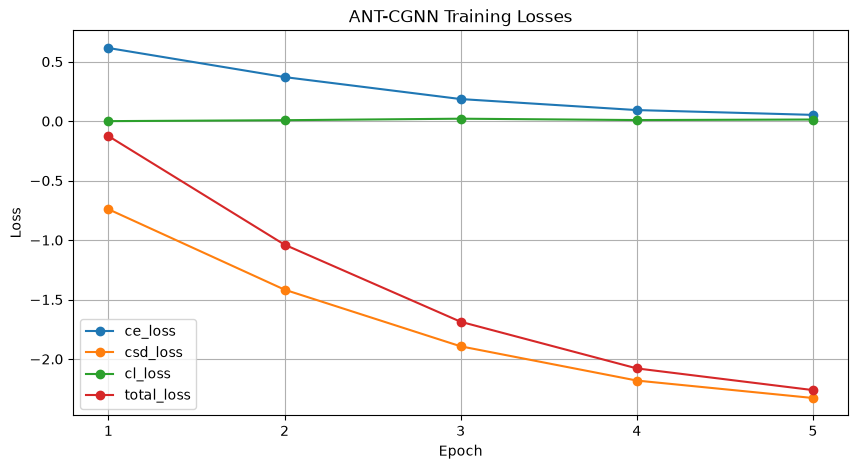

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for name, values in history_ant.items():
    plt.plot(
        range(1, EPOCHS + 1),
        values,
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANT-CGNN Training Losses")
plt.xticks(range(1, EPOCHS + 1))
plt.legend()
plt.grid(True)
plt.show()

In [55]:
# ==========================================
# VALIDATION DATA CHECK
# ==========================================

print("VALIDATION DATA SUMMARY\n")

print("Validation nodes:", len(val_idx))
print("Normal nodes:", (data.y[val_idx] == 0).sum().item())
print("Fraud nodes:", (data.y[val_idx] == 1).sum().item())

print("\nTraining configuration:")
print("Labelled nodes:", len(labelled_1))
print("Labelled fraud nodes:", (data.y[labelled_1] == 1).sum().item())
print("Labelled normal nodes:", (data.y[labelled_1] == 0).sum().item())

VALIDATION DATA SUMMARY

Validation nodes: 11807
Normal nodes: 11266
Fraud nodes: 541

Training configuration:
Labelled nodes: 22
Labelled fraud nodes: 1
Labelled normal nodes: 21


In [56]:
# ==========================================
# ANT-CGNN VALIDATION EVALUATION
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Evaluation mode
csd_ant.eval()
attention_ant.eval()
trust_ant.eval()
aggregation_ant.eval()
classifier_ant.eval()

validation_logits = []
validation_targets = []

validation_batch_size = 16

empty_labelled = torch.empty(0, dtype=torch.long)

with torch.no_grad():

    for start in range(0, len(val_idx), validation_batch_size):

        val_batch_nodes = val_idx[
            start:start + validation_batch_size
        ]

        # Prepare validation batch
        val_batch = prepare_cgnn_batch(
            labelled_nodes=empty_labelled,
            unlabelled_nodes=val_batch_nodes,
            num_unlabelled=len(val_batch_nodes),
            num_neighbors=NUM_NEIGHBORS
        )

        # Forward pass
        val_output = ant_cgnn_forward(
            val_batch["batch_x_std"].to(device),
            val_batch["local_edge_index"].to(device),
            val_batch["seed_local_idx"].to(device)
        )

        # Store predictions and corresponding true labels
        validation_logits.append(
            val_output["original_logits"].cpu()
        )

        validation_targets.append(
            data.y[val_batch["seed_batch"]].cpu()
        )

# Combine all validation batches
validation_logits = torch.cat(validation_logits, dim=0)
y_true = torch.cat(validation_targets, dim=0).numpy()

# Convert logits to predicted classes
y_pred = validation_logits.argmax(dim=1).numpy()

# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)

macro_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

macro_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("ANT-CGNN VALIDATION RESULTS")
print("=" * 40)

print(f"Validation nodes: {len(y_true)}")
print(f"Accuracy:         {accuracy:.4f}")
print(f"Macro-Precision:  {macro_precision:.4f}")
print(f"Macro-Recall:     {macro_recall:.4f}")
print(f"Macro-F1:         {macro_f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Normal", "Fraud"],
    zero_division=0
))

ANT-CGNN VALIDATION RESULTS
Validation nodes: 11807
Accuracy:         0.9542
Macro-Precision:  0.4771
Macro-Recall:     0.5000
Macro-F1:         0.4883

Confusion Matrix:
[[11266     0]
 [  541     0]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.95      1.00      0.98     11266
       Fraud       0.00      0.00      0.00       541

    accuracy                           0.95     11807
   macro avg       0.48      0.50      0.49     11807
weighted avg       0.91      0.95      0.93     11807



In [57]:
# ==========================================
# ANT-CGNN PREDICTION DIAGNOSTICS
# ==========================================

# Convert validation logits to probabilities
fraud_probabilities = torch.softmax(
    validation_logits, dim=1
)[:, 1]

print("FRAUD PROBABILITY DIAGNOSTICS\n")

print("Minimum:",
      fraud_probabilities.min().item())

print("Maximum:",
      fraud_probabilities.max().item())

print("Mean:",
      fraud_probabilities.mean().item())

print("Standard deviation:",
      fraud_probabilities.std().item())

print("\nPrediction distribution:")

print("Predicted normal:",
      (y_pred == 0).sum())

print("Predicted fraud:",
      (y_pred == 1).sum())

print("\nProbability distribution:")

print("Below 0.1:",
      (fraud_probabilities < 0.1).sum().item())

print("0.1 - 0.3:",
      ((fraud_probabilities >= 0.1) &
       (fraud_probabilities < 0.3)).sum().item())

print("0.3 - 0.5:",
      ((fraud_probabilities >= 0.3) &
       (fraud_probabilities < 0.5)).sum().item())

print("0.5 - 0.7:",
      ((fraud_probabilities >= 0.5) &
       (fraud_probabilities < 0.7)).sum().item())

print("Above 0.7:",
      (fraud_probabilities >= 0.7).sum().item())

FRAUD PROBABILITY DIAGNOSTICS

Minimum: 4.3192812054862925e-30
Maximum: 0.48051178455352783
Mean: 0.028055230155587196
Standard deviation: 0.07739803940057755

Prediction distribution:
Predicted normal: 11807
Predicted fraud: 0

Probability distribution:
Below 0.1: 10711
0.1 - 0.3: 772
0.3 - 0.5: 324
0.5 - 0.7: 0
Above 0.7: 0


In [58]:
# ==========================================
# ANT-CGNN THRESHOLD ANALYSIS
# ==========================================

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [0.05, 0.10, 0.15, 0.20, 0.25,
              0.30, 0.35, 0.40, 0.45, 0.50]

print("THRESHOLD ANALYSIS")
print("=" * 75)

print(
    f"{'Threshold':<12}"
    f"{'Precision':<12}"
    f"{'Recall':<12}"
    f"{'Macro-F1':<12}"
    f"{'Fraud Pred.':<12}"
)

for threshold in thresholds:

    predictions = (
        fraud_probabilities.numpy() >= threshold
    ).astype(int)

    precision = precision_score(
        y_true, predictions,
        pos_label=1, zero_division=0
    )

    recall = recall_score(
        y_true, predictions,
        pos_label=1, zero_division=0
    )

    macro_f1_value = f1_score(
        y_true, predictions,
        average="macro", zero_division=0
    )

    fraud_predicted = predictions.sum()

    print(
        f"{threshold:<12.2f}"
        f"{precision:<12.4f}"
        f"{recall:<12.4f}"
        f"{macro_f1_value:<12.4f}"
        f"{fraud_predicted:<12}"
    )

THRESHOLD ANALYSIS
Threshold   Precision   Recall      Macro-F1    Fraud Pred. 
0.05        0.2360      0.6876      0.6438      1576        
0.10        0.3047      0.6174      0.6820      1096        
0.15        0.3745      0.5601      0.7077      809         
0.20        0.4618      0.5139      0.7302      602         
0.25        0.5880      0.4695      0.7508      432         
0.30        0.7160      0.4288      0.7594      324         
0.35        0.8443      0.3309      0.7291      212         
0.40        0.9398      0.2311      0.6762      133         
0.45        0.9455      0.0961      0.5766      55          
0.50        0.0000      0.0000      0.4883      0           


In [59]:
# Evaluation at threshold 0.30

threshold = 0.30

y_pred_30 = (
    fraud_probabilities.numpy() >= threshold
).astype(int)

print("THRESHOLD:", threshold)
print("Accuracy:", accuracy_score(y_true, y_pred_30))
print("Macro-F1:", f1_score(y_true, y_pred_30, average="macro"))
print("Macro-Recall:", recall_score(y_true, y_pred_30, average="macro"))
print("Macro-Precision:", precision_score(y_true, y_pred_30, average="macro"))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred_30))

THRESHOLD: 0.3
Accuracy: 0.9660370966375879
Macro-F1: 0.7593945182625064
Macro-Recall: 0.7103346630776586
Macro-Precision: 0.8445700192340153

Confusion Matrix:
[[11174    92]
 [  309   232]]


In [60]:
# ==========================================
# ANT-CGNN: ONE COMPLETE TRAINING EPOCH
# ==========================================

csd_ant.train()
attention_ant.train()
trust_ant.train()
aggregation_ant.train()
classifier_ant.train()

epoch_losses = []

permutation = torch.randperm(len(unlabelled_1))
shuffled_nodes = unlabelled_1[permutation]

for start in range(0, len(shuffled_nodes), NUM_UNLABELLED):

    unlabelled_batch = shuffled_nodes[
        start:start + NUM_UNLABELLED
    ]

    batch = prepare_cgnn_batch(
        labelled_nodes=labelled_1,
        unlabelled_nodes=unlabelled_batch,
        num_unlabelled=len(unlabelled_batch),
        num_neighbors=NUM_NEIGHBORS
    )

    optimizer_ant.zero_grad()

    output = ant_cgnn_forward(
        batch["batch_x_std"].to(device),
        batch["local_edge_index"].to(device),
        batch["seed_local_idx"].to(device)
    )

    losses = calculate_ant_cgnn_losses(batch, output)

    losses["total_loss"].backward()
    optimizer_ant.step()

    epoch_losses.append([
        losses["ce_loss"].item(),
        losses["csd_loss"].item(),
        losses["cl_loss"].item(),
        losses["total_loss"].item()
    ])

epoch_average = np.mean(epoch_losses, axis=0)

print("COMPLETE TRAINING EPOCH FINISHED")
print("Batches:", len(epoch_losses))
print("Average CE:", epoch_average[0])
print("Average CSD:", epoch_average[1])
print("Average CL:", epoch_average[2])
print("Average Total Loss:", epoch_average[3])

COMPLETE TRAINING EPOCH FINISHED
Batches: 245
Average CE: 0.014227967955343217
Average CSD: -2.486291469846453
Average CL: 0.0050858607978745
Average Total Loss: -2.46697765053535


In [61]:
# ==========================================
# ANT-CGNN: 5 FULL TRAINING EPOCHS
# ==========================================

EPOCHS = 5

full_history = []

for epoch in range(EPOCHS):

    csd_ant.train()
    attention_ant.train()
    trust_ant.train()
    aggregation_ant.train()
    classifier_ant.train()

    shuffled_nodes = unlabelled_1[
        torch.randperm(len(unlabelled_1))
    ]

    epoch_losses = []

    for start in range(0, len(shuffled_nodes), NUM_UNLABELLED):

        unlabelled_batch = shuffled_nodes[
            start:start + NUM_UNLABELLED
        ]

        batch = prepare_cgnn_batch(
            labelled_nodes=labelled_1,
            unlabelled_nodes=unlabelled_batch,
            num_unlabelled=len(unlabelled_batch),
            num_neighbors=NUM_NEIGHBORS
        )

        optimizer_ant.zero_grad()

        output = ant_cgnn_forward(
            batch["batch_x_std"].to(device),
            batch["local_edge_index"].to(device),
            batch["seed_local_idx"].to(device)
        )

        losses = calculate_ant_cgnn_losses(batch, output)

        losses["total_loss"].backward()
        optimizer_ant.step()

        epoch_losses.append([
            losses["ce_loss"].item(),
            losses["csd_loss"].item(),
            losses["cl_loss"].item(),
            losses["total_loss"].item()
        ])

    avg = np.mean(epoch_losses, axis=0)
    full_history.append(avg)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"CE: {avg[0]:.4f} | "
        f"CSD: {avg[1]:.4f} | "
        f"CL: {avg[2]:.4f} | "
        f"Total: {avg[3]:.4f}"
    )

print("\nFive complete training epochs finished!")

Epoch 1/5 | CE: 0.0000 | CSD: -2.4991 | CL: 0.0017 | Total: -2.4974
Epoch 2/5 | CE: 0.0001 | CSD: -2.4999 | CL: 0.0002 | Total: -2.4996
Epoch 3/5 | CE: 0.0001 | CSD: -2.5000 | CL: 0.0001 | Total: -2.4997
Epoch 4/5 | CE: 0.0001 | CSD: -2.5000 | CL: 0.0001 | Total: -2.4998
Epoch 5/5 | CE: 0.0000 | CSD: -2.5000 | CL: 0.0001 | Total: -2.4999

Five complete training epochs finished!


In [62]:
# Evaluate at the previously selected threshold
fraud_probabilities = torch.softmax(
    validation_logits, dim=1
)[:, 1]

y_pred_30 = (
    fraud_probabilities.numpy() >= 0.30
).astype(int)

print("UPDATED VALIDATION RESULTS")
print("Accuracy:", accuracy_score(y_true, y_pred_30))
print("Macro-F1:", f1_score(y_true, y_pred_30, average="macro"))
print("Macro-Recall:", recall_score(y_true, y_pred_30, average="macro"))
print("Macro-Precision:", precision_score(y_true, y_pred_30, average="macro"))
print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred_30))

UPDATED VALIDATION RESULTS
Accuracy: 0.9660370966375879
Macro-F1: 0.7593945182625064
Macro-Recall: 0.7103346630776586
Macro-Precision: 0.8445700192340153

Confusion Matrix:
[[11174    92]
 [  309   232]]


In [63]:
print("FRAUD PROBABILITY SUMMARY")

print("Minimum:", fraud_probabilities.min().item())
print("Maximum:", fraud_probabilities.max().item())
print("Mean:", fraud_probabilities.mean().item())
print("Standard deviation:", fraud_probabilities.std().item())

print("\nUnique probability values:",
      torch.unique(fraud_probabilities).numel())

FRAUD PROBABILITY SUMMARY
Minimum: 4.3192812054862925e-30
Maximum: 0.48051178455352783
Mean: 0.028055230155587196
Standard deviation: 0.07739803940057755

Unique probability values: 11807


In [64]:
# ==========================================
# FRAUD VS NORMAL PROBABILITY COMPARISON
# ==========================================

normal_probs = fraud_probabilities[y_true == 0]
fraud_probs = fraud_probabilities[y_true == 1]

print("NORMAL NODES")
print("Mean:", normal_probs.mean().item())
print("Median:", normal_probs.median().item())

print("\nFRAUD NODES")
print("Mean:", fraud_probs.mean().item())
print("Median:", fraud_probs.median().item())

print("\nFraud scores higher than 0.30:")
print((fraud_probs >= 0.30).sum().item())

print("Normal scores higher than 0.30:")
print((normal_probs >= 0.30).sum().item())

NORMAL NODES
Mean: 0.01897788606584072
Median: 7.64148062444292e-05

FRAUD NODES
Mean: 0.21708545088768005
Median: 0.2238447070121765

Fraud scores higher than 0.30:
232
Normal scores higher than 0.30:
92


In [65]:
print("TRAINING LABELLED PREDICTIONS")

csd_ant.eval()
attention_ant.eval()
trust_ant.eval()
aggregation_ant.eval()
classifier_ant.eval()

with torch.no_grad():
    train_batch = prepare_cgnn_batch(
        labelled_1, unlabelled_1, num_unlabelled=16
    )
    train_batch = {
        k: v.to(device) if torch.is_tensor(v) else v
        for k, v in train_batch.items()
    }

    train_output = ant_cgnn_forward(
        train_batch["batch_x_std"],
        train_batch["local_edge_index"],
        train_batch["seed_local_idx"]
    )

    idx = train_batch["labelled_seed_idx"]
    predictions = train_output["original_logits"][idx].argmax(dim=1)
    actual = data.y[train_batch["seed_batch"][:len(idx)]].to(device)

    print("Correct:", (predictions == actual).sum().item(), "/", len(actual))
    print("Actual fraud:", (actual == 1).sum().item())
    print("Predicted fraud:", (predictions == 1).sum().item())

TRAINING LABELLED PREDICTIONS
Correct: 22 / 22
Actual fraud: 1
Predicted fraud: 1


In [66]:
print("ATTENTION STATISTICS")
print("Mean:", train_output["attention_scores"].mean().item())
print("Std:", train_output["attention_scores"].std().item())

print("\nNEIGHBOUR TRUST STATISTICS")
print("Mean:", train_output["trust_scores"].mean().item())
print("Std:", train_output["trust_scores"].std().item())
print("Minimum:", train_output["trust_scores"].min().item())
print("Maximum:", train_output["trust_scores"].max().item())

ATTENTION STATISTICS
Mean: 0.10326086729764938
Std: 0.0239734947681427

NEIGHBOUR TRUST STATISTICS
Mean: 0.7972350120544434
Std: 0.15839974582195282
Minimum: 0.5419477820396423
Maximum: 0.999994158744812


In [67]:
# Check attention sums for each destination node
src, dst = train_batch["local_edge_index"]
attention = train_output["attention_scores"].squeeze()

attention_sums = torch.zeros(
    train_batch["batch_x_std"].size(0),
    device=device
)

attention_sums.index_add_(0, dst, attention)

valid_nodes = torch.bincount(
    dst, minlength=len(attention_sums)
) > 0

print("Mean attention sum:",
      attention_sums[valid_nodes].mean().item())

print("Minimum attention sum:",
      attention_sums[valid_nodes].min().item())

print("Maximum attention sum:",
      attention_sums[valid_nodes].max().item())

Mean attention sum: 1.0
Minimum attention sum: 0.9999998807907104
Maximum attention sum: 1.0000001192092896


In [68]:
# Compare trust scores across the two classes of destination nodes

src, dst = train_batch["local_edge_index"]
trust = train_output["trust_scores"].squeeze()

node_labels = data.y[train_batch["sampled_nodes"]].to(device)
destination_labels = node_labels[dst]

normal_trust = trust[destination_labels == 0]
fraud_trust = trust[destination_labels == 1]

print("Normal destination nodes:")
print("Mean trust:", normal_trust.mean().item())

print("\nFraud destination nodes:")
print("Mean trust:", fraud_trust.mean().item())

Normal destination nodes:
Mean trust: 0.8039935827255249

Fraud destination nodes:
Mean trust: 0.5552774667739868


In [73]:
validation_trust_scores = []
validation_destination_labels = []

csd_ant.eval()
attention_ant.eval()
trust_ant.eval()
aggregation_ant.eval()
classifier_ant.eval()

with torch.no_grad():
    for start in range(0, len(val_idx), 16):
        val_nodes = val_idx[start:start + 16]

        batch = prepare_cgnn_batch(
            torch.tensor([], dtype=torch.long),
            val_nodes,
            num_unlabelled=len(val_nodes)
        )

        batch = {
            k: v.to(device) if torch.is_tensor(v) else v
            for k, v in batch.items()
        }

        output = ant_cgnn_forward(
            batch["batch_x_std"],
            batch["local_edge_index"],
            batch["seed_local_idx"]
        )

        _, dst = batch["local_edge_index"]

        destination_labels = data.y[
            batch["sampled_nodes"]
        ][dst]

        validation_trust_scores.append(
            output["trust_scores"].squeeze().cpu()
        )

        validation_destination_labels.append(
            destination_labels.cpu()
        )

trust = torch.cat(validation_trust_scores)
labels = torch.cat(validation_destination_labels)

print("Normal mean trust:",
      trust[labels == 0].mean().item())

print("Fraud mean trust:",
      trust[labels == 1].mean().item())

Normal mean trust: 0.7915986776351929
Fraud mean trust: 0.6579352617263794


In [72]:
for name, value in globals().copy().items():
    if any(word in name.lower() for word in ["val", "test"]):
        if torch.is_tensor(value):
            print(name, value.shape, value.dtype)

val_idx torch.Size([11807]) torch.int64
test_idx torch.Size([23615]) torch.int64
value torch.Size([]) torch.float32
validation_logits torch.Size([11807, 2]) torch.float32
val_batch_nodes torch.Size([15]) torch.int64
valid_nodes torch.Size([405]) torch.bool


In [75]:
print("AGGREGATION MODULE")
print(aggregation_ant)

print("\nTRAINABLE PARAMETERS")
for name, param in aggregation_ant.named_parameters():
    print(name, param.shape)

AGGREGATION MODULE
AggregationUpdate(
  (update_projection): Linear(in_features=32, out_features=32, bias=True)
)

TRAINABLE PARAMETERS
update_projection.weight torch.Size([32, 32])
update_projection.bias torch.Size([32])


In [77]:
def ant_cgnn_forward_no_trust(batch_x, edge_index, seed_local_idx):

    normal, abnormal = csd_ant(batch_x)
    node_features = normal + abnormal

    # Keep attention
    messages, attention_scores = attention_ant(
        normal, abnormal, edge_index
    )

    # Remove adaptive trust weighting
    weighted_messages = messages

    # Original aggregation
    updated_features = aggregation_ant(
        node_features, weighted_messages, edge_index
    )

    original_seed_features = updated_features[seed_local_idx]
    original_logits = classifier_ant(original_seed_features)

    # Keep SFP
    normal_perturbed, abnormal_perturbed = sfp_ant(
        normal, abnormal, attention_scores, edge_index
    )

    normal_updated = aggregation_ant(
        node_features, normal_perturbed, edge_index
    )

    abnormal_updated = aggregation_ant(
        node_features, abnormal_perturbed, edge_index
    )

    normal_logits = classifier_ant(
        normal_updated[seed_local_idx]
    )

    abnormal_logits = classifier_ant(
        abnormal_updated[seed_local_idx]
    )

    return {
        "original_logits": original_logits,
        "normal_logits": normal_logits,
        "abnormal_logits": abnormal_logits,
        "normal_features": normal,
        "abnormal_features": abnormal,
        "attention_scores": attention_scores,
        "original_nodes": updated_features
    }


In [79]:
import copy

# Reproducible initialisation
torch.manual_seed(27)

# Create fresh model components
csd_initial = CategorySemanticDecomposition(
    input_dim=10, hidden_dim=64
).to(device)

attention_initial = DenoisingAttention(
    hidden_dim=32, attention_dim=32
).to(device)

trust_initial = AdaptiveNeighbourTrust(
    hidden_dim=32
).to(device)

aggregation_initial = AggregationUpdate(
    hidden_dim=32
).to(device)

classifier_initial = CGNNClassifier(
    input_dim=32, hidden_dim=64, num_classes=2
).to(device)

# Identical initial weights for both experiments
csd_full = copy.deepcopy(csd_initial)
csd_no_trust = copy.deepcopy(csd_initial)

attention_full = copy.deepcopy(attention_initial)
attention_no_trust = copy.deepcopy(attention_initial)

trust_full = copy.deepcopy(trust_initial)

aggregation_full = copy.deepcopy(aggregation_initial)
aggregation_no_trust = copy.deepcopy(aggregation_initial)

classifier_full = copy.deepcopy(classifier_initial)
classifier_no_trust = copy.deepcopy(classifier_initial)

print("Matched model initialisations created successfully.")

Matched model initialisations created successfully.
